In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Hodnoty z DS 7
n_per_group = 3839    # ← doplň svoje n z DS 7
p1 = 0.10             # baseline konverzný pomer
alpha = 0.05
n_simulations = 10_000

np.random.seed(42)
print(f"n = {n_per_group}, p = {p1}, simulácií = {n_simulations:,}")

n = 3839, p = 0.1, simulácií = 10,000


In [2]:
p_values = []

for _ in range(n_simulations):
    control   = np.random.binomial(1, p1, n_per_group)
    treatment = np.random.binomial(1, p1, n_per_group)  # rovnaký pomer!
    _, p = stats.ttest_ind(control, treatment)
    p_values.append(p)

fpr = sum(p < alpha for p in p_values) / n_simulations
print(f"False Positive Rate: {fpr:.3f}  (očakávané: ~0.050)")

False Positive Rate: 0.050  (očakávané: ~0.050)


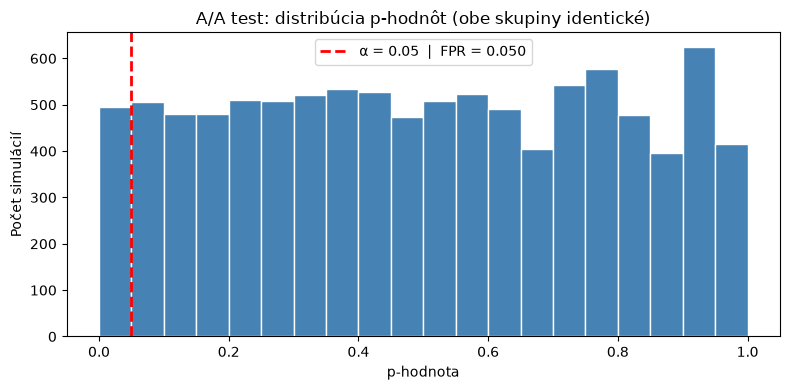

In [3]:
plt.figure(figsize=(8, 4))
plt.hist(p_values, bins=20, edgecolor='white', color='steelblue')
plt.axvline(x=0.05, color='red', linestyle='--', linewidth=2, label=f'α = 0.05  |  FPR = {fpr:.3f}')
plt.xlabel('p-hodnota')
plt.ylabel('Počet simulácií')
plt.title('A/A test: distribúcia p-hodnôt (obe skupiny identické)')
plt.legend()
plt.tight_layout()
plt.savefig('aa_test_pvalues.png', dpi=120)
plt.show()

## Záver

- Simulovaných A/A testov: 10 000
- FPR: ~5 % → sedí na zvolenej hladine α = 0.05
- Distribúcia p-hodnôt je rovnomerná (uniform) – správne správanie testu
- Ak by FPR bol napr. 20 %, znamenalo by to chybu v implementácii testu

**Zajtra (DS 9):** čo sa stane s FPR, ak výsledky sledujeme priebežne (peeking)?